### Data preparation

Turn videos and photos into a clean, labeled dataset in YOLO format.
```

In [3]:
from pathlib import Path
import random
import cv2
import yaml
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
VIDEOS = ROOT / "videos"
FRAMES = ROOT / "data" / "frames"
RAW = ROOT / "data" / "raw_images"
ALL = ROOT / "data" / "all_images"
DATASET = ROOT / "data" / "gas_bottles"   # unzipped export goes here

for p in (VIDEOS, FRAMES, RAW, ALL):
    p.mkdir(parents=True, exist_ok=True)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
print("Project root:", ROOT)

Project root: D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo


#### 1. Extract frames from videos

In [5]:
MAX_FRAMES_PER_VIDEO = 70
START_SEC = 0
END_SEC = None

def extract_frames(video_path, out_dir, max_frames=70, start_sec=0, end_sec=None):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    first = int(start_sec * fps)
    last = min(total, int(end_sec * fps)) if end_sec else total
    step = max(1, (last - first) // max_frames)

    cap.set(cv2.CAP_PROP_POS_FRAMES, first)
    i, saved = first, 0
    while i < last and saved < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        if (i - first) % step == 0:
            cv2.imwrite(str(out_dir / f"{video_path.stem}_{saved:04d}.jpg"), frame)
            saved += 1
        i += 1
    cap.release()
    return saved

videos = sorted(VIDEOS.glob("*.mp4"))
for v in videos:
    print(f"{v.name}: {extract_frames(v, FRAMES, MAX_FRAMES_PER_VIDEO, START_SEC, END_SEC)} frames")

14_55_back_left_cropped.mp4: 70 frames
14_55_back_right_cropped.mp4: 70 frames
14_55_front_cropped.mp4: 70 frames


#### 2. Remove blurry frames and collect all images in one folder

In [ ]:
BLUR_THRESHOLD = 50

def sharpness(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return cv2.Laplacian(img, cv2.CV_64F).var() if img is not None else 0.0

frame_files = [p for p in FRAMES.iterdir() if p.suffix.lower() in IMG_EXT]
scores = {p: sharpness(p) for p in frame_files}
blurry = [p for p, s in scores.items() if s < BLUR_THRESHOLD]
print(f"{len(frame_files)} frames, {len(blurry)} considered blurry (< {BLUR_THRESHOLD})")

import shutil
n = 0
for p in frame_files:
    if p not in blurry:
        shutil.copy(p, ALL / f"frame_{p.name}"); n += 1
for p in RAW.iterdir():
    if p.suffix.lower() in IMG_EXT:
        shutil.copy(p, ALL / f"raw_{p.name}"); n += 1
print(f"{n} images ready in {ALL}")

316 frames, 119 considered blurry (< 50)
197 images ready in D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\data\all_images


### 3. Label the images in CVAT

1. Upload everything in `data/all_images/` to CVAT.
2. Draw one box around each gas bottle, class name `gas_bottle`.
3. Generate a version with a train/valid/test split (e.g. 70/20/10) and export as **YOLO format**.
4. Unzip the export into `data/cvat_batch_1/`

### 4. Check the exported dataset

For now we used `data\gas_hack` - gas Computer Vision Dataset

https://universe.roboflow.com/hack-rhpxr/gas-bsckk/dataset/1

In [ ]:
def split_dir(name):
    for cand in (name, "val" if name == "valid" else name):
        d = DATASET / cand
        if d.exists():
            return d
    return None

for split in ("train", "valid", "test"):
    d = split_dir(split)
    if d is None:
        print(f"{split}: folder not found")
        continue
    imgs = [p for p in (d / "images").iterdir() if p.suffix.lower() in IMG_EXT]
    labels = list((d / "labels").glob("*.txt"))
    boxes = sum(len(l.read_text().strip().splitlines()) for l in labels if l.read_text().strip())
    empty = len(imgs) - len([l for l in labels if l.read_text().strip()])
    print(f"{split:6s} images={len(imgs):4d} label files={len(labels):4d} boxes={boxes:4d} images without boxes={empty}")

train  images=  88 label files=  88 boxes=  88 images without boxes=0
valid  images=  24 label files=  24 boxes=  24 images without boxes=0
test   images=  10 label files=  10 boxes=  10 images without boxes=0


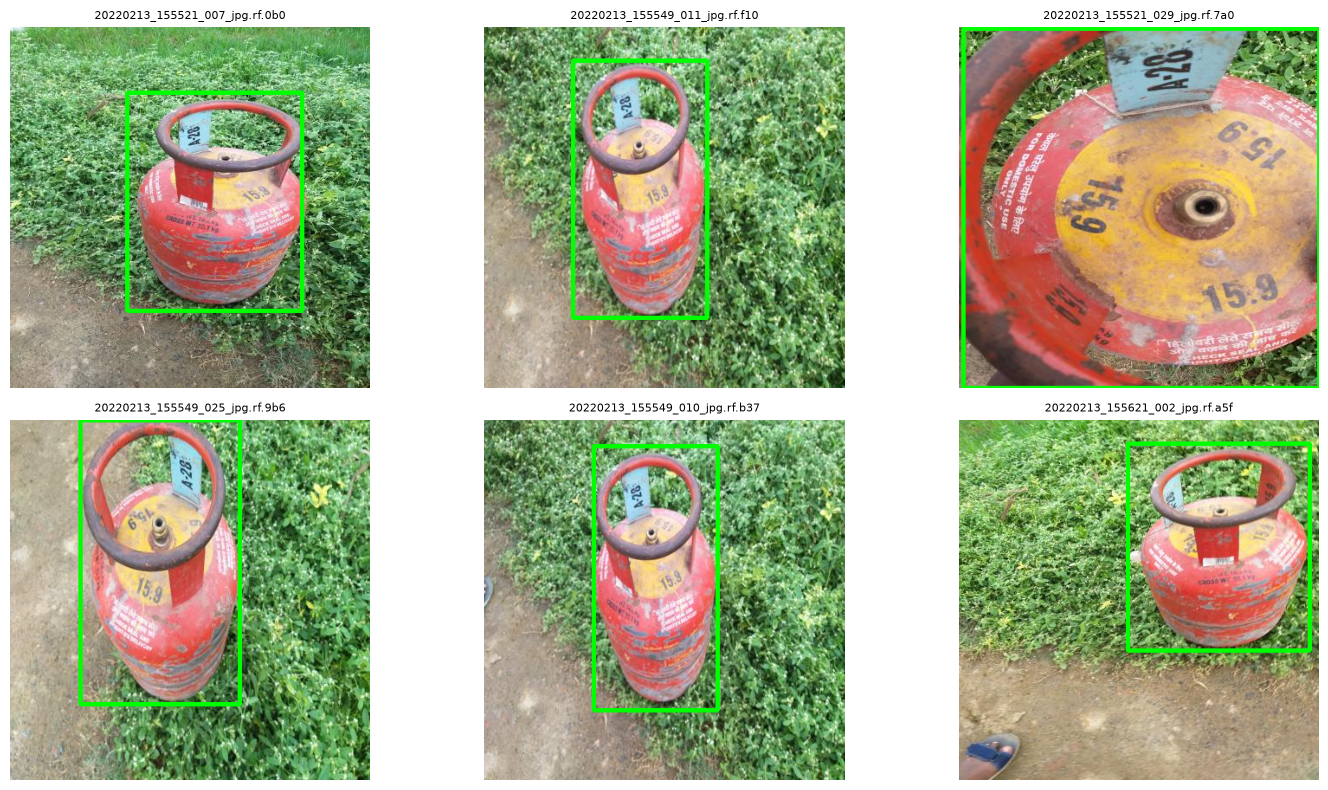

In [ ]:
def show_labeled(split="train", n=6):
    d = split_dir(split)
    imgs = [p for p in (d / "images").iterdir() if p.suffix.lower() in IMG_EXT]
    sample = random.sample(imgs, min(n, len(imgs)))
    cols = 3
    rows = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
    for ax in axes:
        ax.axis("off")
    for ax, p in zip(axes, sample):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        lbl = d / "labels" / (p.stem + ".txt")
        if lbl.exists():
            for line in lbl.read_text().strip().splitlines():
                parts = line.split()
                if len(parts) < 5:
                    continue
                _, cx, cy, bw, bh = map(float, parts[:5])
                x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
                x2, y2 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        ax.imshow(img)
        ax.set_title(p.name[:30], fontsize=8)
    plt.tight_layout()
    plt.show()

show_labeled("train")

### 5. `data.yaml`

In [ ]:
train_d, val_d, test_d = split_dir("train"), split_dir("valid"), split_dir("test")

data = {
    "path": str(DATASET),
    "train": f"{train_d.name}/images",
    "val": f"{val_d.name}/images",
    "names": {0: "gas_bottle"},
}
if test_d is not None:
    data["test"] = f"{test_d.name}/images"

with open(DATASET / "data.yaml", "w") as f:
    yaml.safe_dump(data, f)

print((DATASET / "data.yaml").read_text())

names:
  0: gas_bottle
path: D:\BCS Files\Y3S1\AI Applications MBI38j\Labs\primagaz-yolo\data\gas_bottles
test: test/images
train: train/images
val: valid/images

